# Duration and Convexity of a Multi-Currency Treasury Portfolio Hedged with SOFR Swaps: Macaulay, Modified, Fisher–Weil, Key-Rate, Term-Bucket and Floating-Rate Durations, with a Machine-Learning Revaluation Surrogate

A treasury that holds bonds from many issuers and in many currencies cannot describe its interest-rate risk with one number. A Treasury bond, a supranational floater and a Swiss covered bond all react differently when rates move, and each currency's curve moves on its own. This notebook builds the full family of duration and convexity measures for such a portfolio, shows how swaps to SOFR change them, and checks how well each measure predicts the real gain or loss.

**What it does.** It assembles a $5 billion development-bank-style treasury portfolio from the real holdings of iShares bond funds:

- **U.S. dollar fixed rate:** Treasuries, agencies, municipal bonds, corporates and banks, and emerging-market sovereigns;
- **U.S. dollar floating rate:** SOFR-indexed notes of supranationals, agencies and banks;
- **other hard currencies:** sovereign, supranational, agency, covered and corporate bonds in euros, sterling, yen, Canadian and Australian dollars, Swiss francs, and Swedish, Norwegian and Danish crowns and New Zealand dollars.

For every bond and for the portfolio, before and after hedging, it computes:

1. Macaulay and modified duration and convexity at the bond's yield;
2. **term durations** in their three market senses: the Fisher–Weil duration on the term structure, key-rate (partial) durations, and duration by term bucket;
3. effective duration and convexity from curve shifts, and spread duration;
4. for floating-rate notes, the rate duration to the next reset against the spread duration to maturity;
5. DV01 in dollars by currency, issuer type and term bucket.

The fixed-rate bonds are then swapped into floating rate with overnight-index swaps in each currency (SOFR, €STR, SONIA, TONA, CORRA, AONIA, SARON and the New Zealand OIS), and the foreign currency is hedged back into U.S. dollars.

**Data.** iShares fund holdings (GOVT, AGZ, MUB, IGIB, EMB, FLOT and the international aggregate fund IAGG); swap trades reported to the DTCC public repository; FRED U.S. Treasury yields, SOFR and monthly 3-month and 10-year rates for eleven countries; Yahoo Finance fund prices.

**Methods.** Cash-flow schedules by currency convention, OIS bootstrapping, Nelson–Siegel fits, z-spreads, triangular key-rate bumps, least-squares swap hedges, full revaluation under historical curve scenarios, second-order Taylor approximations, and LightGBM and Keras revaluation surrogates. Empirical durations come from fund price regressions.

**Key output.** Duration and convexity by bond, issuer type and currency; the key-rate and term-bucket profile before and after the swaps; the residual spread risk; the accuracy of each approximation against full revaluation; and the empirical durations of the funds.

## 1. The duration family

For a bond with price $P$, cash flows $CF_i$ at times $t_i$ and yield $y$ compounded $f$ times a year:

- **Macaulay duration** is the present-value-weighted average time of the cash flows:
  $$D_{Mac}=\frac{1}{P}\sum_i t_i\,\frac{CF_i}{(1+y/f)^{f t_i}}.$$
- **Modified duration** is the percentage price change for a change in the bond's own yield: $D_{mod}=D_{Mac}/(1+y/f)$.
- **Convexity** is the second-order term: $\Delta P/P\approx-D_{mod}\,\Delta y+\tfrac12 C\,(\Delta y)^2$.

These yield-based measures assume one flat yield. A portfolio is exposed to **curves**, so the market also uses curve-based measures. The phrase **term duration** is used in three senses:

1. **Term-structure (Fisher–Weil) duration.** Each cash flow is discounted at its own spot rate on the curve, plus the bond's z-spread $s$:
   $$D_{FW}=\frac{1}{P}\sum_i t_i\,CF_i\,e^{-(z(t_i)+s)t_i}.$$
   It equals the sensitivity to a parallel shift of the whole term structure.
2. **Key-rate (partial) durations.** The curve is bumped by 1 bp around one maturity at a time (2, 5, 10 years…) with triangular bumps. They add up to the Fisher–Weil duration, and they show where on the curve the risk sits.
3. **Duration by term bucket.** The portfolio's DV01 is grouped by maturity bucket (0–2, 2–5, 5–10, 10–20, 20+ years), the format of most treasury limit frameworks.

**Effective duration and convexity** come from revaluing the bond after shifting the curve up and down. They capture embedded options, so for callable agency and municipal bonds they can differ from the yield measures. **Spread duration** is the sensitivity to the bond's own spread over the curve.

**Floating-rate notes** have two durations. Their coupon resets to SOFR plus a fixed margin, so their **rate duration** is only the time to the next reset. Their **spread duration**, the sensitivity to the discount margin, runs to maturity.

**Hedging with swaps.** A pay-fixed, receive-overnight swap behaves like a short position in a fixed-rate bond against a floating note worth about par. Its duration is roughly minus that of a bond with the same coupon and maturity. Pairing each fixed-rate bond with such swaps turns it into a synthetic floater: the rate durations collapse towards zero while the credit spread duration stays.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
import torch
import yfinance as yf
import zipfile
from scipy.optimize import brentq, least_squares, nnls

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 130
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

PORTFOLIO_USD = 5e9
ISHARES = {
    "GOVT": "239468",
    "AGZ": "239457",
    "MUB": "239766",
    "IGIB": "239463",
    "EMB": "239572",
    "FLOT": "239534",
    "IAGG": "279626",
}
# target allocation of the portfolio (share of market value)
TARGET = {
    ("USD", "Sovereign"): 0.15,
    ("USD", "Agency"): 0.08,
    ("USD", "Municipal"): 0.04,
    ("USD", "Corporate and bank"): 0.10,
    ("USD", "EM sovereign"): 0.08,
    ("USD", "SOFR floating-rate note"): 0.15,
    ("EUR", None): 0.14,
    ("GBP", None): 0.06,
    ("JPY", None): 0.05,
    ("CAD", None): 0.04,
    ("AUD", None): 0.03,
    ("CHF", None): 0.025,
    ("SEK", None): 0.02,
    ("NOK", None): 0.015,
    ("DKK", None): 0.01,
    ("NZD", None): 0.01,
}
BONDS_PER_BUCKET = 25
ANNUAL_PAY = {"EUR", "CHF", "SEK", "NOK", "DKK"}
OIS = {
    "USD": "SOFR",
    "EUR": "EuroSTR",
    "GBP": "SONIA",
    "JPY": "TONA",
    "CAD": "CORRA",
    "AUD": "AONIA",
    "CHF": "SARON",
    "NZD": "NZIONA",
}
KEYS = [1, 2, 3, 5, 7, 10, 20, 30]
HEDGE_TENORS = [1, 2, 3, 5, 7, 10, 20, 30]
SOV_CAP = 0.6  # cap on sovereigns inside each foreign currency
BUCKETS = [(0, 2), (2, 5), (5, 10), (10, 20), (20, 100)]
DTCC_URL = (
    "https://kgc0418-tdw-data-0.s3.amazonaws.com/cftc/eod/"
    "CFTC_CUMULATIVE_RATES_{d:%Y_%m_%d}.zip"
)
N_DTCC_DAYS = 5
COUNTRY = {
    "USD": "US",
    "EUR": "DE",
    "GBP": "GB",
    "JPY": "JP",
    "CAD": "CA",
    "AUD": "AU",
    "CHF": "CH",
    "SEK": "SE",
    "NOK": "NO",
    "DKK": "DK",
    "NZD": "NZ",
}

print(
    f"keras {keras.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

/home/claude/pkg0/venv/lib/python3.12/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


keras 3.15.1 · lightgbm 4.7.0 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Bond holdings

The latest holdings files of seven iShares funds supply the bonds, with coupon, maturity, yield, currency and the provider's own duration figures:

- **GOVT:** U.S. Treasuries;
- **AGZ:** U.S. agencies (some callable);
- **MUB:** municipal bonds (mostly callable);
- **IGIB:** investment-grade corporates and banks;
- **EMB:** emerging-market sovereigns in dollars;
- **FLOT:** floating-rate notes, mostly on SOFR;
- **IAGG:** non-U.S. investment-grade bonds in local currencies.

Only fixed-income lines are kept; cash, futures and FX forwards are dropped.

**Issuer types.**

- Treasury lines are sovereigns.
- Lines located in "Supranational" are supranationals.
- The rest of IAGG's "Government Related" lines are agencies and local authorities.
- Covered and corporate bonds keep their sector.

In [3]:
def fetch_holdings(ticker):
    url = (
        f"https://www.ishares.com/us/products/{ISHARES[ticker]}/fund/"
        "latest-holdings.csv"
    )
    lines = requests.get(url, headers=BROWSER_HEADERS, timeout=120).text
    lines = lines.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    head = next(i for i, l in enumerate(lines) if l.startswith("Name,"))
    t = pd.read_csv(
        io.StringIO("\n".join(lines[head:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"], t["as_of"] = ticker, as_of
    return t


RAW = pd.concat(
    [
        cached(
            f"ishares_{t}", lambda t=t: fetch_holdings(t), max_age_hours=24 * 3
        )
        for t in ISHARES
    ],
    ignore_index=True,
)
num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", ""), errors="coerce"
)
H = RAW[RAW["Asset Class"] == "Fixed Income"].copy()
H["ccy"] = H["Market Currency"].fillna(H["Currency"])
for c, src in [
    ("mv", "Market Value"),
    ("wt", "Weight (%)"),
    ("coupon", "Coupon (%)"),
    ("ytm", "YTM (%)"),
    ("dur_ishares", "Duration"),
    ("mod_ishares", "Mod. Duration"),
    ("ytw", "Yield to Worst (%)"),
    ("fx", "FX Rate"),
]:
    H[c] = num(H[src])
H["maturity"] = pd.to_datetime(
    H["Maturity"], format="%b %d, %Y", errors="coerce"
)
VAL_DATE = pd.to_datetime(H["as_of"].iloc[0], format="%b %d, %Y")
H["T"] = (H["maturity"] - VAL_DATE).dt.days / 365.25


def issuer_type(r):
    if r["fund"] == "FLOT":
        return "SOFR floating-rate note"
    if r["fund"] == "GOVT":
        return "Sovereign"
    if r["fund"] == "AGZ":
        return "Agency"
    if r["fund"] == "MUB":
        return "Municipal"
    if r["fund"] == "IGIB":
        return "Corporate and bank"
    if r["fund"] == "EMB":
        return "EM sovereign"
    if r["Sector"] == "Treasury":
        return "Sovereign"
    if r["Location"] == "Supranational":
        return "Supranational"
    if r["Sector"] == "Government Related":
        return "Agency and local authority"
    if r["Sector"] == "Covered":
        return "Covered bond"
    return "Corporate and bank"


H["issuer"] = H.apply(issuer_type, axis=1)
H = H[(H["T"] > 0.05) & H["ytm"].notna() & H["coupon"].notna() & (H["mv"] > 0)]
H = H[(H["fund"] != "IAGG") | H["ccy"].isin([k[0] for k in TARGET])]
print(f"Holdings as of {VAL_DATE:%Y-%m-%d}: {len(H):,} bond lines")
H.groupby(["fund", "ccy"]).size().rename("lines").to_frame().T

Holdings as of 2026-10-27: 21,063 bond lines


fund   AGZ  EMB FLOT GOVT IAGG                                            \
ccy    USD  USD  USD  USD  AUD   CAD CHF DKK   EUR  GBP  JPY NOK NZD SEK   
lines  117  615  555  229  391  1127  64  15  6002  775  252  15  21  40   

fund   IGIB   MUB  
ccy     USD   USD  
lines  3064  7781

## 4. The portfolio

Each dollar issuer type takes its 25 largest holdings. Each foreign currency is split across issuer types in proportion to the international fund's holdings, with sovereigns capped at 60% so that supranationals, agencies, covered bonds and corporates are represented, and takes the 10 largest bonds of each type. Bonds are weighted in proportion to the fund's market value and scaled to the target share of $5 billion:

- 60% in dollars: 45% at fixed rate across five issuer types, and 15% in SOFR floaters;
- 40% in ten other currencies, led by the euro (14%), sterling (6%) and the yen (5%).

Positions are held in local currency; the face amount is the dollar market value times the FX rate divided by the bond's price.

In [4]:
picks = []
for (ccy, iss), w in TARGET.items():
    if ccy == "USD":
        pool = H[
            (H["ccy"] == "USD") & (H["issuer"] == iss) & (H["fund"] != "IAGG")
        ]
        top = pool.nlargest(BONDS_PER_BUCKET, "mv").copy()
        top["usd_mv"] = PORTFOLIO_USD * w * top["mv"] / top["mv"].sum()
        top["bucket"] = f"{ccy} {iss}"
        picks.append(top)
        continue
    pool = H[(H["ccy"] == ccy) & (H["fund"] == "IAGG")]
    share = pool.groupby("issuer")["mv"].sum() / pool["mv"].sum()
    if share.get("Sovereign", 0) > SOV_CAP and len(share) > 1:
        rest = share.drop("Sovereign")
        share = pd.concat([
            pd.Series({"Sovereign": SOV_CAP}),
            rest / rest.sum() * (1 - SOV_CAP),
        ])
    for issuer_, sh in share.items():
        top = pool[pool["issuer"] == issuer_].nlargest(10, "mv").copy()
        top["usd_mv"] = PORTFOLIO_USD * w * sh * top["mv"] / top["mv"].sum()
        top["bucket"] = f"{ccy} {issuer_}"
        picks.append(top)
PF = pd.concat(picks, ignore_index=True)
PF["fx"] = np.where(PF["ccy"] == "USD", 1.0, PF["fx"])
PF["frn"] = PF["issuer"] == "SOFR floating-rate note"
PF["freq"] = np.where(PF["frn"], 4, np.where(PF["ccy"].isin(ANNUAL_PAY), 1, 2))
COMP = (
    PF.pivot_table(
        index="issuer",
        columns="ccy",
        values="usd_mv",
        aggfunc="sum",
        fill_value=0,
    )
    / PORTFOLIO_USD
)
print(
    f"{len(PF)} bonds · {PF['ccy'].nunique()} currencies · "
    f"{PF['issuer'].nunique()} issuer types"
)
(COMP * 100).round(1)

439 bonds · 11 currencies · 9 issuer types


ccy,AUD,CAD,CHF,DKK,EUR,GBP,JPY,NOK,NZD,SEK,USD
issuer,,,,,,,,,,,
Agency,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00
Agency and local authority,1.10,1.60,0.10,0.00,1.90,0.40,0.00,0.60,0.40,0.00,0.00
Corporate and bank,0.30,0.80,0.10,0.00,2.80,1.60,2.00,0.00,0.00,0.00,10.00
Covered bond,0.00,0.00,1.20,0.40,1.00,0.00,0.00,0.00,0.00,0.80,0.00
EM sovereign,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.00
Municipal,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.00
SOFR floating-rate note,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,15.00
Sovereign,1.50,1.50,1.10,0.60,7.20,3.60,3.00,0.90,0.60,1.20,15.00
Supranational,0.10,0.00,0.00,0.00,1.10,0.30,0.00,0.00,0.00,0.00,0.00


## 5. Discount curves

Every currency gets one base curve, and each bond's own credit and liquidity premium is its z-spread over that curve.

- **Overnight-index swap curves** for eight currencies come from swap trades reported to the DTCC public repository over the last five business days. Spot-starting new trades are kept, mapped to standard tenors, and cleaned of outliers by median absolute deviation; the notional-weighted median is the par rate. The curves are bootstrapped with annual fixed payments; tenors without trades are interpolated, and the long end is held flat beyond the last quote.
- **Currencies with fewer than five traded OIS tenors** (the Swedish, Norwegian and Danish crowns have almost none, and the Australian and New Zealand dollars had too few in the window) use a Nelson–Siegel fit to the yields of their own government bonds in the holdings.

In [5]:
GRID_M = [
    1,
    3,
    6,
    9,
    12,
    18,
    24,
    36,
    48,
    60,
    72,
    84,
    96,
    108,
    120,
    144,
    180,
    240,
    300,
    360,
    480,
]


def fetch_dtcc():
    keep = [
        "Action type",
        "Execution Timestamp",
        "Effective Date",
        "Expiration Date",
        "Package indicator",
        "Notional amount-Leg 1",
        "Fixed rate-Leg 1",
        "Fixed rate-Leg 2",
        "UPI FISN",
        "UPI Underlier Name",
        "Non-standardized term indicator",
    ]
    out, day = [], dt.date.today()
    while len(out) < N_DTCC_DAYS:
        day -= dt.timedelta(days=1)
        if day.weekday() >= 5:
            continue
        try:
            r = requests.get(DTCC_URL.format(d=day), timeout=120)
            r.raise_for_status()
        except requests.RequestException:
            continue
        z = zipfile.ZipFile(io.BytesIO(r.content))
        raw = pd.read_csv(z.open(z.namelist()[0]), dtype=str, low_memory=False)
        f = raw["UPI FISN"].fillna("")
        x = raw.loc[
            f.str.startswith("NA/Swap OIS"),
            [c for c in keep if c in raw.columns],
        ].copy()
        x["file_date"] = day.isoformat()
        out.append(x)
    return pd.concat(out, ignore_index=True)


D = cached("dtcc_ois", fetch_dtcc, max_age_hours=24 * 3)
D["ccy"] = D["UPI FISN"].str[-3:]
D = D[D["ccy"].isin(OIS)]
D = D[
    D.apply(
        lambda r: OIS[r["ccy"]].lower()
        in str(r["UPI Underlier Name"]).lower().replace("-", ""),
        axis=1,
    )
]
D["rate"] = num(D["Fixed rate-Leg 1"]).fillna(num(D["Fixed rate-Leg 2"]))
D["notional"] = num(
    D["Notional amount-Leg 1"].str.replace(r"[^0-9.]", "", regex=True)
)
D["notional"] = D["notional"].fillna(1e6).clip(1e5, 1e10)
D["trade"] = pd.to_datetime(D["Execution Timestamp"].str[:10], errors="coerce")
D["eff"] = pd.to_datetime(D["Effective Date"], errors="coerce")
D["exp"] = pd.to_datetime(D["Expiration Date"], errors="coerce")
D = D[
    (D["Action type"] == "NEWT")
    & (D["Package indicator"] != "TRUE")
    & (D["Non-standardized term indicator"] != "TRUE")
    & ((D["eff"] - D["trade"]).dt.days.between(0, 7))
    & D["rate"].between(-0.01, 0.12)
]
D["len_m"] = (D["exp"] - D["eff"]).dt.days / 30.4375
g = np.array(GRID_M)
near = np.abs(D["len_m"].to_numpy()[:, None] - g[None, :])
D["tenor_m"] = g[near.argmin(1)]
D = D[near.min(1) <= np.maximum(0.25, 0.012 * D["tenor_m"])]


def robust_quote(x):
    med = x["rate"].median()
    mad = (x["rate"] - med).abs().median()
    x = x[(x["rate"] - med).abs() <= max(3 * 1.4826 * mad, 1e-4)]
    o = np.argsort(x["rate"].to_numpy())
    w = x["notional"].to_numpy()[o].cumsum()
    return pd.Series({
        "rate": x["rate"].to_numpy()[o][np.searchsorted(w, w[-1] / 2)],
        "trades": len(x),
    })


QUOTES = (
    D.groupby(["ccy", "tenor_m"])
    .apply(robust_quote, include_groups=False)
    .reset_index()
)
QUOTES = QUOTES[QUOTES["trades"] >= 2]
print(f"{len(D):,} clean OIS trades")
QUOTES.pivot(index="tenor_m", columns="ccy", values="rate").mul(100).round(3)

5,843 clean OIS trades


ccy,AUD,CAD,CHF,EUR,GBP,JPY,USD
tenor_m,,,,,,,
1,4.71,2.46,NaN,2.45,NaN,NaN,3.93
3,4.80,2.54,NaN,2.54,4.03,1.31,4.06
6,NaN,NaN,NaN,2.66,4.22,1.44,4.21
9,NaN,NaN,NaN,2.77,4.38,NaN,4.34
12,4.97,2.96,0.12,2.90,4.54,1.64,4.46
18,NaN,3.12,NaN,2.96,4.66,1.76,4.51
24,NaN,3.21,0.33,3.02,4.75,1.88,4.55
36,NaN,3.32,NaN,3.08,4.76,2.02,4.57
48,NaN,3.38,NaN,3.11,4.79,2.11,4.54


In [6]:
ZT = np.r_[np.arange(0.25, 1.0, 0.25), np.arange(1, 61, 1.0)]


def bootstrap_ois(q):
    """Par OIS rates (tenor years, rate) -> continuous zero rates on ZT."""
    T, R = q["tenor_m"].to_numpy() / 12, q["rate"].to_numpy()
    par = lambda t: np.interp(t, T, R)
    z = {}
    for t in ZT[ZT < 1]:
        z[t] = np.log(1 + par(t) * t) / t
    dfs = []
    for n in range(1, 61):
        k = par(float(n))
        df = (1 - k * sum(dfs)) / (1 + k)
        dfs.append(df)
        z[float(n)] = -np.log(df) / n
    return np.array([z[t] for t in ZT])


def ns_zero(t, b0, b1, b2, tau):
    x = t / tau
    f = (1 - np.exp(-x)) / x
    return b0 + b1 * f + b2 * (f - np.exp(-x))


def fit_ns(bonds):
    t = bonds["T"].to_numpy()
    y = np.log(1 + bonds["ytm"].to_numpy() / 100)
    res = least_squares(
        lambda p: ns_zero(t, *p) - y,
        x0=[y.mean(), -0.01, 0.0, 2.0],
        bounds=([-0.05, -0.2, -0.3, 0.2], [0.2, 0.2, 0.3, 30]),
    )
    return ns_zero(ZT, *res.x), np.sqrt(np.mean(res.fun**2))


CURVES, CURVE_SRC = {}, {}
for ccy in sorted(PF["ccy"].unique()):
    q = QUOTES[QUOTES["ccy"] == ccy].sort_values("tenor_m")
    if ccy in OIS and q["tenor_m"].nunique() >= 5:
        CURVES[ccy] = bootstrap_ois(q)
        CURVE_SRC[ccy] = (
            f"{OIS[ccy]} OIS, {len(q)} tenors to {q['tenor_m'].max() / 12:g}y"
        )
    else:
        gov = H[(H["ccy"] == ccy) & (H["issuer"] == "Sovereign")]
        CURVES[ccy], err = fit_ns(gov)
        CURVE_SRC[ccy] = (
            f"Nelson–Siegel on {len(gov)} government bonds "
            f"(RMSE {err * 1e4:.0f} bp)"
        )
CURVE_TAB = pd.DataFrame({
    c: {
        "source": CURVE_SRC[c],
        "2y zero (%)": CURVES[c][ZT == 2][0] * 100,
        "10y zero (%)": CURVES[c][ZT == 10][0] * 100,
        "30y zero (%)": CURVES[c][ZT == 30][0] * 100,
    }
    for c in CURVES
}).T
CURVE_TAB.round({"2y zero (%)": 2, "10y zero (%)": 2, "30y zero (%)": 2})

,source,2y zero (%),10y zero (%),30y zero (%)
AUD,Nelson–Siegel on 29 government bonds (RMSE 1 bp),4.75,5.03,5.48
CAD,"CORRA OIS, 15 tenors to 30y",3.17,3.58,3.79
CHF,"SARON OIS, 8 tenors to 30y",0.33,0.71,0.77
DKK,Nelson–Siegel on 10 government bonds (RMSE 3 bp),2.70,3.12,3.28
EUR,"EuroSTR OIS, 20 tenors to 30y",2.98,3.18,3.08
GBP,"SONIA OIS, 20 tenors to 40y",4.64,4.80,4.99
JPY,"TONA OIS, 18 tenors to 30y",1.86,2.70,3.50
NOK,Nelson–Siegel on 12 government bonds (RMSE 2 bp),4.67,4.34,4.06
NZD,Nelson–Siegel on 14 government bonds (RMSE 3 bp),3.98,4.89,5.44
SEK,Nelson–Siegel on 11 government bonds (RMSE 2 bp),2.70,3.04,3.23


## 6. Bond analytics

**Cash flows.** Coupons are annual for bonds in euros, Swiss francs and the Scandinavian currencies and semi-annual elsewhere, and are scheduled backwards from maturity. Accrued interest and day counts are left out, so prices are full prices on an actual/365 time axis.

**Yield measures.** Macaulay and modified duration and convexity are computed at each bond's yield.

**Curve measures.**

1. The z-spread over the base curve is solved so that the curve price equals the yield price.
2. From it come the Fisher–Weil duration, key-rate durations (triangular 1 bp bumps centred on 1, 2, 3, 5, 7, 10, 20 and 30 years) and the effective duration and convexity (±25 bp parallel shifts).
3. Spread duration comes from a ±25 bp shift of the z-spread.

**Floating-rate notes.** Their yield-based (Macaulay and modified) durations are the time to the next reset, since the coupon is only fixed until then. For the curve measures, the next coupon is fixed at the current rate. Later coupons are the forward overnight rate plus the quoted margin, and the note is discounted at the curve plus a discount margin equal to the quoted margin, so it prices near par. The next payment date is the first quarterly date counting back from maturity.

In [7]:
def schedule(T, freq):
    n = int(np.floor(T * freq + 1e-9)) + 1
    t = T - np.arange(n) / freq
    return np.sort(t[t > 1e-6])


def zero_at(ccy, t, shift=None):
    z = np.interp(
        t, ZT, CURVES[ccy], left=CURVES[ccy][0], right=CURVES[ccy][-1]
    )
    return z if shift is None else z + shift(t)


def key_bump(k, size=1e-4):
    i = KEYS.index(k)
    lo = KEYS[i - 1] if i else 0.0
    hi = KEYS[i + 1] if i < len(KEYS) - 1 else None

    def f(t):
        up = np.clip((t - lo) / (k - lo), 0, 1)
        if hi is None:
            return size * np.where(t <= k, up, 1.0)
        return size * np.where(t <= k, up, np.clip((hi - t) / (hi - k), 0, 1))

    return f


def cash_flows(r):
    t = schedule(r["T"], r["freq"])
    if not r["frn"]:
        cf = np.full(len(t), r["coupon"] / r["freq"])
        cf[-1] += 100
        return t, cf
    return t, None


def frn_price(r, t, shift=None, ds=0.0):
    """FRN: next coupon fixed, later coupons = forward OIS + margin,
    discounted at OIS + discount margin."""
    z = zero_at("USD", t, shift)
    dfo = np.exp(-z * t)
    df = np.exp(-(z + r["dm"] + ds) * t)
    acc = 1 / r["freq"]
    fwd = np.r_[0.0, dfo[:-1] / dfo[1:] - 1]
    cpn = np.where(
        np.arange(len(t)) == 0,
        r["coupon"] / 100 * acc,
        fwd + r["margin"] * acc,
    )
    return 100 * (np.sum(cpn * df) + df[-1])


def curve_price(r, shift=None, ds=0.0):
    t, cf = cash_flows(r)
    if r["frn"]:
        return frn_price(r, t, shift, ds)
    z = zero_at(r["ccy"], t, shift)
    return np.sum(cf * np.exp(-(z + r["zspread"] + ds) * t))


def analytics(r):
    r = r.copy()
    t, cf = cash_flows(r)
    f, y = r["freq"], r["ytm"] / 100
    out = {}
    if r["frn"]:
        sofr = float(SOFR_NOW)
        r["margin"] = max(r["coupon"] / 100 - sofr, -0.005)
        r["dm"] = r["margin"]
        P = frn_price(r, t)
        # yield measures of a floater: the coupon is fixed only to the reset
        out.update(
            macaulay=t[0],
            modified=t[0] / (1 + r["coupon"] / 400),
            convexity_yield=0.0,
            yield_price=P,
        )
        r["zspread"] = r["dm"]
    else:
        v = (1 + y / f) ** (-f * t)
        P = np.sum(cf * v)
        mac = np.sum(t * cf * v) / P
        conv = np.sum(cf * v * t * (t + 1 / f)) / (P * (1 + y / f) ** 2)
        out.update(
            macaulay=mac,
            modified=mac / (1 + y / f),
            convexity_yield=conv,
            yield_price=P,
        )
        r["zspread"] = brentq(
            lambda s: np.sum(cf * np.exp(-(zero_at(r["ccy"], t) + s) * t)) - P,
            -0.2,
            0.5,
        )
    base = curve_price(r)
    up = curve_price(r, lambda x: 0 * x + 25e-4)
    dn = curve_price(r, lambda x: 0 * x - 25e-4)
    out["effective"] = (dn - up) / (2 * base * 25e-4)
    out["convexity_effective"] = (up + dn - 2 * base) / (base * 25e-4**2)
    out["spread_duration"] = (
        curve_price(r, ds=-25e-4) - curve_price(r, ds=25e-4)
    ) / (2 * base * 25e-4)
    if not r["frn"]:
        z = zero_at(r["ccy"], t)
        w = cf * np.exp(-(z + r["zspread"]) * t)
        out["fisher_weil"] = np.sum(t * w) / np.sum(w)
    else:
        out["fisher_weil"] = out["effective"]
    for k in KEYS:
        out[f"krd_{k}"] = (base - curve_price(r, key_bump(k))) / (base * 1e-4)
    out["zspread_bp"] = r["zspread"] * 1e4
    out["zspread"] = r["zspread"]
    out["margin"] = r.get("margin", np.nan)
    out["dm"] = r.get("dm", np.nan)
    out["next_reset"] = t[0] if r["frn"] else np.nan
    return pd.Series(out)


SOFR_NOW = (
    cached(
        "sofr",
        lambda: fred.get_series("SOFR").dropna().rename("sofr").to_frame(),
        max_age_hours=24,
    )["sofr"].iloc[-1]
    / 100
)
t0 = time.time()
AN = PF.join(PF.apply(analytics, axis=1))
AN["sum_krd"] = AN[[f"krd_{k}" for k in KEYS]].sum(axis=1)
AN["usd_dv01"] = AN["usd_mv"] * AN["effective"] * 1e-4
print(f"analytics for {len(AN)} bonds in {time.time() - t0:.1f}s")
CHECK = pd.Series({
    "median |modified − iShares mod. duration| (fixed)": (
        (AN.loc[~AN["frn"], "modified"] - AN.loc[~AN["frn"], "mod_ishares"])
        .abs()
        .median()
    ),
    "median |Fisher–Weil − sum of KRDs|": (
        (AN.loc[~AN["frn"], "fisher_weil"] - AN.loc[~AN["frn"], "sum_krd"])
        .abs()
        .median()
    ),
    "median |effective − Fisher–Weil| (fixed)": (
        (AN.loc[~AN["frn"], "effective"] - AN.loc[~AN["frn"], "fisher_weil"])
        .abs()
        .median()
    ),
})
CHECK.round(4)

analytics for 439 bonds in 0.8s


median |modified − iShares mod. duration| (fixed)   0.00
median |Fisher–Weil − sum of KRDs|                  0.01
median |effective − Fisher–Weil| (fixed)            0.00
dtype: float64

## 7. Portfolio duration before hedging

Portfolio measures are market-value weighted in U.S. dollars, since duration is a percentage sensitivity. The dollar DV01 is the dollar value of a 1 bp parallel rise in all curves. The tables show the measures by issuer type and by currency, the key-rate profile, and the DV01 by term bucket.

In [8]:
MEAS = [
    "macaulay",
    "modified",
    "fisher_weil",
    "effective",
    "convexity_yield",
    "convexity_effective",
    "spread_duration",
    "dur_ishares",
]


def wavg(df, cols):
    w = df["usd_mv"] / df["usd_mv"].sum()
    out = {}
    for c in cols:
        ok_ = df[c].notna()
        out[c] = (
            np.sum(df.loc[ok_, c] * w[ok_]) / w[ok_].sum()
            if ok_.any()
            else np.nan
        )
    return pd.Series(out)


def summary(df, by):
    rows = {
        k: pd.concat([
            pd.Series({
                "weight": g["usd_mv"].sum() / PORTFOLIO_USD,
                "DV01 ($k)": g["usd_dv01"].sum() / 1e3,
            }),
            wavg(g, MEAS),
        ])
        for k, g in df.groupby(by)
    }
    tot = pd.concat([
        pd.Series({"weight": 1.0, "DV01 ($k)": df["usd_dv01"].sum() / 1e3}),
        wavg(df, MEAS),
    ])
    rows["Portfolio"] = tot
    return pd.DataFrame(rows).T


BY_ISSUER = summary(AN, "issuer")
BY_CCY = summary(AN, "ccy")
BY_ISSUER.round(3)

,weight,DV01 ($k),macaulay,modified,fisher_weil,effective,convexity_yield,convexity_effective,spread_duration,dur_ishares
Agency,0.08,117.65,2.94,2.87,2.94,2.94,12.22,11.36,2.94,2.84
Agency and local authority,0.06,147.66,4.85,4.71,4.84,4.84,38.27,37.01,4.84,4.75
Corporate and bank,0.18,497.07,5.63,5.47,5.62,5.62,42.81,42.20,5.62,5.19
Covered bond,0.03,71.49,4.25,4.16,4.25,4.25,36.08,33.12,4.25,4.22
EM sovereign,0.08,283.44,7.10,6.81,7.08,7.09,77.82,80.31,7.09,5.96
Municipal,0.04,199.14,9.97,9.74,9.95,9.96,167.97,171.20,9.96,8.30
SOFR floating-rate note,0.15,8.92,0.12,0.12,0.12,0.12,0.00,0.02,1.90,0.02
Sovereign,0.36,845.39,4.67,4.55,4.67,4.67,43.84,42.95,4.67,4.57
Supranational,0.02,38.37,4.73,4.56,4.72,4.72,35.24,33.69,4.72,4.64
Portfolio,1.00,"2,209.14",4.42,4.30,4.42,4.42,41.49,41.12,4.69,4.12


In [9]:
BY_CCY.round(3)

,weight,DV01 ($k),macaulay,modified,fisher_weil,effective,convexity_yield,convexity_effective,spread_duration,dur_ishares
AUD,0.03,65.64,4.38,4.26,4.38,4.38,25.47,24.67,4.38,4.18
CAD,0.04,115.95,5.81,5.69,5.80,5.80,57.71,57.03,5.80,5.53
CHF,0.03,94.84,7.59,7.53,7.58,7.59,103.00,96.95,7.59,7.57
DKK,0.01,22.18,4.44,4.30,4.43,4.43,47.94,46.60,4.43,4.37
EUR,0.14,244.85,3.50,3.37,3.50,3.50,18.93,16.95,3.50,3.39
GBP,0.06,112.51,3.76,3.66,3.75,3.75,29.88,29.49,3.75,3.58
JPY,0.05,118.00,4.72,4.66,4.72,4.72,31.56,30.05,4.72,4.67
NOK,0.01,41.20,5.49,5.24,5.49,5.49,41.16,39.64,5.49,5.37
NZD,0.01,22.45,4.50,4.40,4.49,4.49,31.65,30.68,4.49,4.39
SEK,0.02,35.86,3.59,3.48,3.59,3.59,24.11,22.01,3.59,3.54


In [10]:
def bucket_dv01(df, value_col="usd_mv"):
    """DV01 by term bucket from key-rate DV01s spread to buckets."""
    out = {}
    for lo, hi in BUCKETS:
        tot = 0.0
        for k in KEYS:
            share = 1.0 if lo < k <= hi else 0.0
            tot += share * (df[value_col] * df[f"krd_{k}"]).sum() * 1e-4
        out[f"{lo}–{hi}y" if hi < 100 else f"{lo}y+"] = tot / 1e3
    return pd.Series(out)


KRD_DV01 = pd.DataFrame({
    c: {
        f"{k}y": (g["usd_mv"] * g[f"krd_{k}"]).sum() * 1e-4 / 1e3 for k in KEYS
    }
    for c, g in AN.groupby("ccy")
})
KRD_DV01["Total"] = KRD_DV01.sum(axis=1)
TERM_BUCKET = pd.DataFrame({c: bucket_dv01(g) for c, g in AN.groupby("ccy")})
TERM_BUCKET["Total"] = TERM_BUCKET.sum(axis=1)
FRN_TAB = (
    AN[AN["frn"]]
    .assign(margin_bp=lambda d: (d["coupon"] / 100 - SOFR_NOW) * 1e4)[[
        "Name",
        "T",
        "coupon",
        "margin_bp",
        "next_reset",
        "effective",
        "spread_duration",
    ]]
    .describe()
    .T[["mean", "50%", "min", "max"]]
)
print("Key-rate DV01 by currency ($ thousands per bp):")
KRD_DV01.round(1)

Key-rate DV01 by currency ($ thousands per bp):


,AUD,CAD,CHF,DKK,EUR,GBP,JPY,NOK,NZD,SEK,USD,Total
1y,1.30,1.70,0.90,0.80,13.80,6.80,2.70,0.60,0.50,1.60,34.10,64.70
2y,4.70,4.70,2.20,0.40,24.50,14.20,5.20,1.20,2.30,3.60,70.20,133.20
3y,12.50,13.50,7.80,4.50,60.90,26.20,15.20,6.40,3.70,10.20,106.90,267.70
5y,20.50,22.90,8.40,3.00,76.20,18.70,30.20,6.00,4.50,6.60,172.50,369.50
7y,18.90,25.20,17.90,3.70,54.20,15.30,33.30,12.50,6.20,4.70,262.70,454.50
10y,6.60,25.10,25.20,4.30,10.90,14.70,30.90,13.20,4.00,6.40,355.00,496.20
20y,1.00,13.30,20.60,2.80,3.50,7.20,0.00,1.30,0.60,2.60,241.30,294.00
30y,0.00,9.40,11.70,2.60,0.00,9.30,0.00,0.00,0.70,0.00,82.90,116.60


In [11]:
print("DV01 by term bucket ($ thousands per bp) — duration by term:")
TERM_BUCKET.round(1)

DV01 by term bucket ($ thousands per bp) — duration by term:


,AUD,CAD,CHF,DKK,EUR,GBP,JPY,NOK,NZD,SEK,USD,Total
0–2y,6.00,6.40,3.10,1.20,38.30,21.00,7.90,1.80,2.80,5.20,104.20,197.90
2–5y,33.00,36.40,16.20,7.50,137.10,44.80,45.40,12.40,8.20,16.80,279.40,637.20
5–10y,25.50,50.30,43.10,7.90,65.20,30.00,64.10,25.70,10.20,11.10,617.70,950.60
10–20y,1.00,13.30,20.60,2.80,3.50,7.20,0.00,1.30,0.60,2.60,241.30,294.00
20y+,0.00,9.40,11.70,2.60,0.00,9.30,0.00,0.00,0.70,0.00,82.90,116.60


In [12]:
print("SOFR floating-rate notes: rate duration (to reset) vs spread duration:")
FRN_TAB.round(3)

SOFR floating-rate notes: rate duration (to reset) vs spread duration:


,mean,50%,min,max
T,2.07,1.94,0.21,4.31
coupon,4.23,4.24,4.02,4.56
margin_bp,27.72,29.00,7.00,61.00
next_reset,0.12,0.10,0.01,0.24
effective,0.12,0.10,0.01,0.25
spread_duration,1.94,1.86,0.21,3.91


## 8. Hedging with overnight-index swaps

For each currency, pay-fixed OIS swaps at the eight key tenors (1, 2, 3, 5, 7, 10, 20 and 30 years) are sized by non-negative least squares to offset the key-rate DV01 profile of the fixed-rate bonds. Where the base curve is a government curve (SEK, NOK, DKK, AUD and NZD here), the swaps are priced off it as a stand-in for the OIS curve.

A payer swap is modelled as a floating leg worth par with zero rate duration, minus a fixed-rate bond paying the par swap rate annually. Its key-rate durations are computed with the same bumps as the bonds.

The foreign-currency positions are also hedged into dollars with FX forwards rolled every three months. This removes the FX delta and adds only a short-dated dollar and local rate exposure, which is left out here.

In [13]:
def par_swap_rate(ccy, T):
    t = np.arange(1, int(round(T)) + 1, dtype=float)
    df = np.exp(-zero_at(ccy, t) * t)
    return (1 - df[-1]) / df.sum()


def swap_krd(ccy, T):
    """Key-rate DV01 per 1 notional of a payer OIS swap (positive = gains
    when rates rise)."""
    k = par_swap_rate(ccy, T)
    t = np.arange(1, int(round(T)) + 1, dtype=float)

    def fixed_leg(shift=None):
        z = zero_at(ccy, t, shift)
        df = np.exp(-z * t)
        return k * df.sum() + df[-1]

    base = fixed_leg()
    return np.array([(base - fixed_leg(key_bump(kk))) for kk in KEYS]), k


HEDGES, SWAP_ROWS = {}, []
for ccy, g in AN[~AN["frn"]].groupby("ccy"):
    target = np.array(
        [(g["usd_mv"] * g[f"krd_{k}"]).sum() * 1e-4 for k in KEYS]
    )
    A = np.column_stack([swap_krd(ccy, T)[0] for T in HEDGE_TENORS])
    notional, _ = nnls(A, target)
    resid = target - A @ notional
    HEDGES[ccy] = {"target": target, "notional": notional, "resid": resid}
    for T, n in zip(HEDGE_TENORS, notional):
        if n > 0:
            SWAP_ROWS.append({
                "currency": ccy,
                "tenor (y)": T,
                "notional ($m)": n / 1e6,
                "par rate": swap_krd(ccy, T)[1],
                "curve": (
                    "OIS" if "OIS" in CURVE_SRC[ccy] else "government proxy"
                ),
            })
SWAPS = pd.DataFrame(SWAP_ROWS)
POST_KRD = pd.DataFrame({
    c: pd.Series(h["resid"] / 1e3, index=[f"{k}y" for k in KEYS])
    for c, h in HEDGES.items()
})
frn_krd = pd.Series({
    f"{k}y": (
        (AN.loc[AN["frn"], "usd_mv"] * AN.loc[AN["frn"], f"krd_{k}"]).sum()
        * 1e-4
        / 1e3
    )
    for k in KEYS
})
POST_KRD["USD"] = POST_KRD.get("USD", 0) + frn_krd
POST_KRD["Total"] = POST_KRD.sum(axis=1)
pre_dv01 = KRD_DV01.loc[:, "Total"].sum()
post_dv01 = POST_KRD["Total"].sum()
spread_dv01 = (AN["usd_mv"] * AN["spread_duration"]).sum() * 1e-4 / 1e3
HEDGE_SUM = pd.Series({
    "rate DV01 before ($k/bp)": pre_dv01,
    "rate DV01 after ($k/bp)": post_dv01,
    "sum of |key-rate DV01| after ($k/bp)": POST_KRD["Total"].abs().sum(),
    "portfolio effective duration before": (
        pre_dv01 * 1e3 / (PORTFOLIO_USD * 1e-4)
    ),
    "portfolio effective duration after": (
        post_dv01 * 1e3 / (PORTFOLIO_USD * 1e-4)
    ),
    "spread DV01 (unchanged by swaps, $k/bp)": spread_dv01,
    "portfolio spread duration": spread_dv01 * 1e3 / (PORTFOLIO_USD * 1e-4),
    "swap notional ($bn)": SWAPS["notional ($m)"].sum() / 1e3,
})
print(f"{len(SWAPS)} swaps across {SWAPS['currency'].nunique()} currencies")
HEDGE_SUM.round(3)

82 swaps across 11 currencies


rate DV01 before ($k/bp)                  2,196.36
rate DV01 after ($k/bp)                       1.51
sum of |key-rate DV01| after ($k/bp)          1.51
portfolio effective duration before           4.39
portfolio effective duration after            0.00
spread DV01 (unchanged by swaps, $k/bp)   2,343.04
portfolio spread duration                     4.69
swap notional ($bn)                           4.25
dtype: float64

In [14]:
print("Residual key-rate DV01 after the swaps ($ thousands per bp):")
POST_KRD.round(2)

Residual key-rate DV01 after the swaps ($ thousands per bp):


,AUD,CAD,CHF,DKK,EUR,GBP,JPY,NOK,NZD,SEK,USD,Total
1y,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,1.44,1.44
2y,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,0.03,0.03
3y,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.03,0.03
5y,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.01,0.01
7y,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00
10y,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
20y,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00
30y,0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00


## 9. How good are the approximations? Full revaluation under historical scenarios

**Scenarios.** Every 12-month change since 2002 in each country's 3-month and 10-year rates (FRED, OECD series) is a joint historical scenario across the eleven currencies. Each currency's curve moves by the 3-month change at the short end and the 10-year change from ten years out, linearly in between. All 270 scenarios are used, along with versions scaled by 1.5 and 2 to probe the tails, about 800 in all.

**Revaluation.** Each scenario fully reprices every bond (and every swap). Spreads and FX are held fixed, so only interest-rate risk is measured.

**Approximations compared against the exact P&L of the unhedged portfolio:**

1. **modified duration only**, applying the portfolio's duration to the dollar-weighted average shift;
2. **duration plus convexity** on the same average shift;
3. **key-rate durations plus convexity, per currency**;
4. **LightGBM**, trained on the scenario shifts (two numbers per currency) of 70% of the scenarios;
5. **a Keras network** on the same inputs.

The machine-learning models are tested on the other 30%.

In [15]:
def fetch_oecd():
    ids = {}
    for c, k in COUNTRY.items():
        ids[f"{c}_10y"] = f"IRLTLT01{k}M156N"
        ids[f"{c}_3m"] = f"IR3TIB01{k}M156N"
    out = {}
    for n, s in ids.items():
        out[n] = fred.get_series(s)
        time.sleep(0.2)
    return pd.DataFrame(out)


OECD = cached("oecd_rates", fetch_oecd, max_age_hours=24 * 7) / 100
OECD.index = pd.to_datetime(OECD.index)
R = OECD.loc["2002-04":].ffill(limit=2)
CH12 = (R - R.shift(12)).dropna()
base_sc = CH12.to_numpy()
SC = np.vstack([base_sc, 1.5 * base_sc, 2.0 * base_sc])
SC_NAMES = list(CH12.columns)
print(
    f"{len(CH12)} historical 12-month scenarios ({CH12.index.min():%Y-%m}"
    f" → {CH12.index.max():%Y-%m}), {len(SC)} with scaled versions"
)

276 historical 12-month scenarios (2003-04 → 2026-03), 828 with scaled versions


In [16]:
CCYS = sorted(COUNTRY)
CIDX = {
    c: (SC_NAMES.index(f"{c}_3m"), SC_NAMES.index(f"{c}_10y")) for c in CCYS
}


def shift_fn(d3, d10):
    return lambda t: d3 + (d10 - d3) * np.clip((t - 0.25) / 9.75, 0, 1)


ROWS = [r for _, r in AN.iterrows()]


def portfolio_pnl(sc, hedged=False):
    """Exact P&L ($) for one scenario vector."""
    pnl = 0.0
    for r in ROWS:
        i3, i10 = CIDX[r["ccy"]]
        f = shift_fn(sc[i3], sc[i10])
        base = curve_price(r)
        pnl += r["usd_mv"] * (curve_price(r, f) / base - 1)
    if hedged:
        for ccy, h in HEDGES.items():
            i3, i10 = CIDX[ccy]
            f = shift_fn(sc[i3], sc[i10])
            for T, n in zip(HEDGE_TENORS, h["notional"]):
                if n <= 0:
                    continue
                k = par_swap_rate(ccy, T)
                t = np.arange(1, T + 1, dtype=float)
                leg = (
                    lambda s=None: k * np.exp(-zero_at(ccy, t, s) * t).sum()
                    + np.exp(-zero_at(ccy, t, s) * T)[-1]
                )
                pnl += n * (leg() - leg(f))
    return pnl


t0 = time.time()
PNL = np.array([portfolio_pnl(s) for s in SC])
PNL_H = np.array([portfolio_pnl(s, hedged=True) for s in SC])
print(f"{len(SC)} full revaluations (×2) in {time.time() - t0:.0f}s")

828 full revaluations (×2) in 67s


In [17]:
w_ccy = AN.groupby("ccy")["usd_mv"].sum() / PORTFOLIO_USD
D_eff = (AN["usd_mv"] * AN["effective"]).sum() / PORTFOLIO_USD
C_eff = (AN["usd_mv"] * AN["convexity_effective"]).sum() / PORTFOLIO_USD
KRD_C = {
    c: np.array([(g["usd_mv"] * g[f"krd_{k}"]).sum() for k in KEYS])
    for c, g in AN.groupby("ccy")
}
CONV_C = {
    c: (g["usd_mv"] * g["convexity_effective"]).sum()
    for c, g in AN.groupby("ccy")
}


def approx(sc):
    avg = sum(
        w_ccy.get(c, 0) * (sc[CIDX[c][0]] + sc[CIDX[c][1]]) / 2 for c in CCYS
    )
    d_only = -PORTFOLIO_USD * D_eff * avg
    d_conv = d_only + 0.5 * PORTFOLIO_USD * C_eff * avg**2
    krd = 0.0
    for c in KRD_C:
        f = shift_fn(sc[CIDX[c][0]], sc[CIDX[c][1]])
        sh = np.array([f(float(k)) for k in KEYS])
        par = np.mean(sh)
        krd += -np.sum(KRD_C[c] * sh) + 0.5 * CONV_C[c] * par**2
    return d_only, d_conv, krd


AP = np.array([approx(s) for s in SC])
idx = rng.permutation(len(SC))
tr, te = idx[: int(0.7 * len(SC))], idx[int(0.7 * len(SC)) :]
gbm = lgb.LGBMRegressor(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=10,
    metric="l2",
    verbose=-1,
    random_state=SEED,
).fit(SC[tr] * 100, PNL[tr] / 1e6)
p_gbm = gbm.predict(SC * 100) * 1e6
inp = keras.Input((SC.shape[1],))
h_ = keras.layers.Dense(64, activation="silu")(inp)
h_ = keras.layers.Dense(64, activation="silu")(h_)
NN = keras.Model(inp, keras.layers.Dense(1)(h_))
NN.compile(optimizer=keras.optimizers.Adam(2e-3), loss="mse")
NN.fit(
    (SC[tr] * 100).astype("float32"),
    (PNL[tr] / 1e6).astype("float32"),
    epochs=400,
    batch_size=32,
    verbose=0,
    validation_split=0.15,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=40, restore_best_weights=True)
    ],
)
p_nn = NN.predict((SC * 100).astype("float32"), verbose=0).ravel() * 1e6


def err(pred, sel):
    e = (pred[sel] - PNL[sel]) / 1e6
    return {
        "mean |error| ($m)": np.mean(np.abs(e)),
        "max |error| ($m)": np.max(np.abs(e)),
        "error / |P&L| (median)": np.median(
            np.abs(e) * 1e6 / np.abs(PNL[sel]).clip(1e5)
        ),
    }


worst = te[np.argsort(PNL[te])[:20]]
APPROX = pd.DataFrame({
    "Modified duration only": err(AP[:, 0], te),
    "Duration + convexity": err(AP[:, 1], te),
    "Key-rate durations + convexity": err(AP[:, 2], te),
    "LightGBM": err(p_gbm, te),
    "Keras network": err(p_nn, te),
}).T
APPROX["mean |error| on the 20 worst test scenarios ($m)"] = [
    np.mean(np.abs(p[worst] - PNL[worst])) / 1e6
    for p in [AP[:, 0], AP[:, 1], AP[:, 2], p_gbm, p_nn]
]
RISK = pd.Series({
    "unhedged: P&L 5th pct ($m)": np.percentile(PNL[: len(base_sc)], 5) / 1e6,
    "hedged: P&L 5th pct ($m)": np.percentile(PNL_H[: len(base_sc)], 5) / 1e6,
    "unhedged: s.d. ($m)": PNL[: len(base_sc)].std() / 1e6,
    "hedged: s.d. ($m)": PNL_H[: len(base_sc)].std() / 1e6,
    "variance removed by the swaps": (
        1 - PNL_H[: len(base_sc)].var() / PNL[: len(base_sc)].var()
    ),
})
print(f"Test scenarios: {len(te)} (20 worst used for the tail check)")
APPROX.round(3)

Test scenarios: 249 (20 worst used for the tail check)


,mean |error| ($m),max |error| ($m),error / |P&L| (median),mean |error| on the 20 worst test scenarios ($m)
Modified duration only,53.05,341.58,0.29,161.31
Duration + convexity,46.51,207.59,0.28,61.92
Key-rate durations + convexity,8.95,105.43,0.03,42.50
LightGBM,15.15,245.44,0.08,32.64
Keras network,1.97,32.09,0.01,3.16


In [18]:
RISK.round(3)

unhedged: P&L 5th pct ($m)      -296.21
hedged: P&L 5th pct ($m)          -2.68
unhedged: s.d. ($m)              160.64
hedged: s.d. ($m)                  1.61
variance removed by the swaps      1.00
dtype: float64

## 10. Empirical durations

Model durations assume that only the base curve moves. The market also moves spreads, often in the opposite direction. The **empirical duration** of each fund is minus the slope of a regression of its daily returns on daily changes in the 10-year Treasury yield, over the last two years. It is compared with the fund's reported average effective duration.

In [19]:
def fetch_prices():
    px = yf.download(
        list(ISHARES), period="3y", auto_adjust=True, progress=False
    )["Close"]
    return px


PX = cached("fund_prices", fetch_prices, max_age_hours=24)
PX.index = pd.to_datetime(PX.index)
DGS = (
    cached(
        "dgs10_daily",
        lambda: fred.get_series("DGS10", observation_start="2023-01-01")
        .rename("dgs10")
        .to_frame(),
        max_age_hours=24,
    )["dgs10"]
    / 100
)
DGS.index = pd.to_datetime(DGS.index)
ret = PX.pct_change()
dy = DGS.diff().reindex(ret.index)
ok = ret.index >= ret.index.max() - pd.Timedelta(days=730)
EMP = {}
for tk in ISHARES:
    x = pd.concat([ret[tk], dy], axis=1).loc[ok].dropna()
    b = np.polyfit(x.iloc[:, 1], x.iloc[:, 0], 1)[0]
    corr = x.corr().iloc[0, 1]
    rep = RAW[(RAW["fund"] == tk) & (RAW["Asset Class"] == "Fixed Income")]
    w = num(rep["Market Value"])
    EMP[tk] = {
        "reported effective duration": (
            np.nansum(num(rep["Duration"]) * w) / w.sum()
        ),
        "empirical duration (vs 10y UST)": -b,
        "correlation with Δ10y": corr,
    }
EMP = pd.DataFrame(EMP).T
EMP["empirical / reported"] = (
    EMP["empirical duration (vs 10y UST)"] / EMP["reported effective duration"]
)
EMP.round(2)

,reported effective duration,empirical duration (vs 10y UST),correlation with Δ10y,empirical / reported
GOVT,5.51,5.21,-0.89,0.94
AGZ,3.44,3.00,-0.81,0.87
MUB,7.42,3.90,-0.71,0.53
IGIB,5.89,5.60,-0.89,0.95
EMB,6.36,5.31,-0.62,0.83
FLOT,0.01,-0.04,0.02,-2.63
IAGG,6.27,2.85,-0.75,0.46


## 11. Charts and dashboard

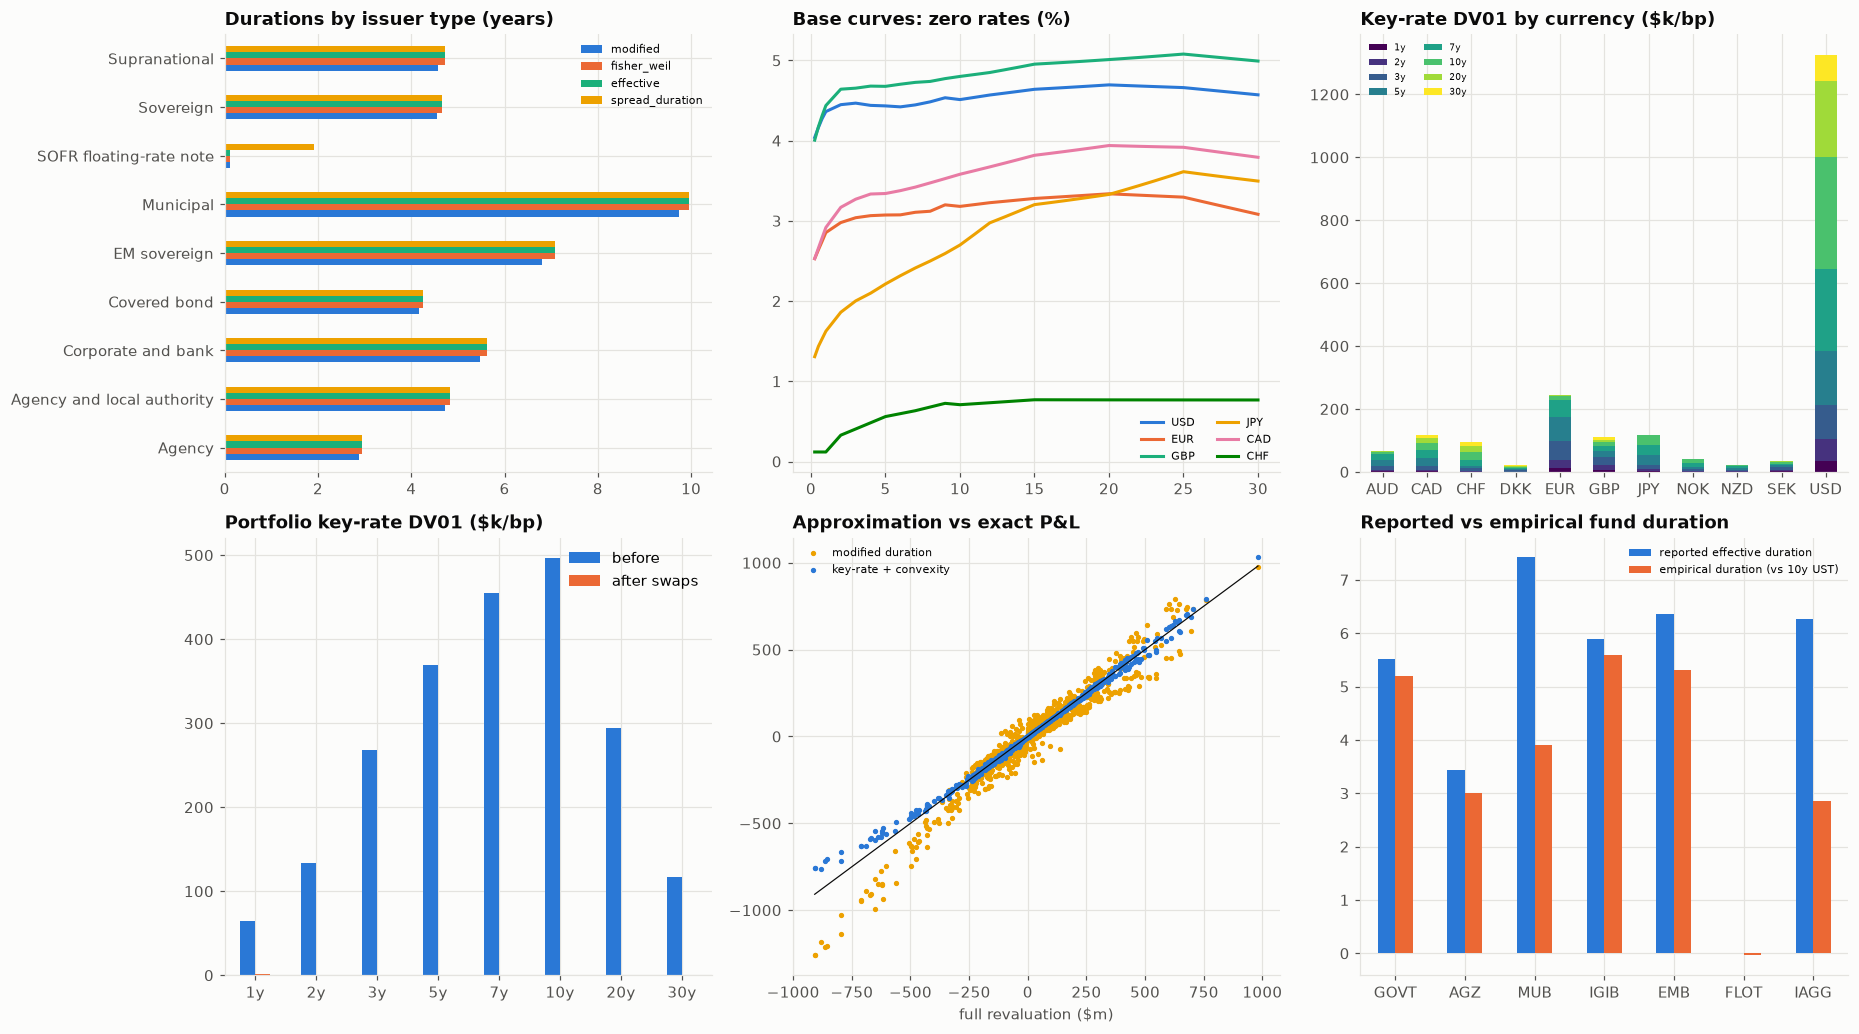

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
BY_ISSUER.drop("Portfolio")[
    ["modified", "fisher_weil", "effective", "spread_duration"]
].plot.barh(ax=a, color=PALETTE[:4])
a.set_title("Durations by issuer type (years)")
a.legend(fontsize=7)
a = ax[0, 1]
for c, col in zip(["USD", "EUR", "GBP", "JPY", "CAD", "CHF"], PALETTE):
    a.plot(ZT[ZT <= 30], CURVES[c][ZT <= 30] * 100, color=col, label=c)
a.legend(fontsize=7, ncol=2)
a.set_title("Base curves: zero rates (%)")
a = ax[0, 2]
KRD_DV01.drop(columns="Total").T.plot.bar(
    stacked=True, ax=a, colormap="viridis", rot=0
)
a.set_title("Key-rate DV01 by currency ($k/bp)")
a.legend(fontsize=6, ncol=2)
a = ax[1, 0]
pd.DataFrame(
    {"before": KRD_DV01["Total"], "after swaps": POST_KRD["Total"]}
).plot.bar(ax=a, color=PALETTE[:2], rot=0)
a.set_title("Portfolio key-rate DV01 ($k/bp)")
a = ax[1, 1]
a.scatter(
    PNL / 1e6, AP[:, 0] / 1e6, s=6, color=PALETTE[3], label="modified duration"
)
a.scatter(
    PNL / 1e6,
    AP[:, 2] / 1e6,
    s=6,
    color=PALETTE[0],
    label="key-rate + convexity",
)
lim = [PNL.min() / 1e6, PNL.max() / 1e6]
a.plot(lim, lim, color=INK, lw=0.8)
a.legend(fontsize=7)
a.set_xlabel("full revaluation ($m)")
a.set_title("Approximation vs exact P&L")
a = ax[1, 2]
EMP[
    ["reported effective duration", "empirical duration (vs 10y UST)"]
].plot.bar(ax=a, color=PALETTE[:2], rot=0)
a.set_title("Reported vs empirical fund duration")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_duration_convexity")
plt.show()

In [21]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Duration measures by currency (years)",
        "Duration by term bucket ($k/bp)",
        "Key-rate DV01 before and after swaps ($k/bp)",
        "Historical-scenario P&L: unhedged vs hedged ($m)",
    ),
)
for m_, col in zip(
    ["modified", "fisher_weil", "effective", "spread_duration"], PALETTE
):
    dash.add_trace(
        go.Bar(x=BY_CCY.index, y=BY_CCY[m_], name=m_, marker_color=col), 1, 1
    )
for c_, col in zip(TERM_BUCKET.drop(columns="Total").columns, PALETTE * 2):
    dash.add_trace(
        go.Bar(
            x=TERM_BUCKET.index,
            y=TERM_BUCKET[c_],
            name=c_,
            marker_color=col,
            showlegend=False,
        ),
        1,
        2,
    )
dash.add_trace(
    go.Bar(
        x=KRD_DV01.index,
        y=KRD_DV01["Total"],
        name="before",
        marker_color=PALETTE[0],
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=POST_KRD.index,
        y=POST_KRD["Total"],
        name="after swaps",
        marker_color=PALETTE[1],
    ),
    2,
    1,
)
dash.add_trace(
    go.Histogram(
        x=PNL[: len(base_sc)] / 1e6,
        name="unhedged",
        marker_color=PALETTE[3],
        opacity=0.6,
    ),
    2,
    2,
)
dash.add_trace(
    go.Histogram(
        x=PNL_H[: len(base_sc)] / 1e6,
        name="hedged",
        marker_color=PALETTE[2],
        opacity=0.6,
    ),
    2,
    2,
)
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Multi-currency treasury portfolio: duration and convexity",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 12. Reading the results and limitations

**The portfolio.** 439 bonds in 11 currencies, built from holdings dated 27 October 2026:

- 60% in dollars: 15% Treasuries, 8% agencies, 4% municipal bonds, 10% corporates and banks, 8% EM sovereigns and 15% SOFR floaters;
- 40% abroad, with euro, sterling and yen the largest.

Abroad, sovereigns are about 60% of each currency, and supranationals, agencies, covered bonds and corporates make up the rest. The OIS curves come from 5,843 clean swap trades. The Swedish, Norwegian, Danish, Australian and New Zealand curves are Nelson–Siegel fits to government bonds, with errors of 1–3 bp.

**The engine is consistent.** Across the fixed-rate bonds:

- the median gap between our modified duration and the provider's is 0.00 years;
- the key-rate durations add up to the Fisher–Weil duration within 0.01 years;
- the effective duration (±25 bp) matches the Fisher–Weil duration.

For bullet bonds, the curve measures and the yield measures are the same risk seen two ways.

**Duration by issuer type** (years, market-value weighted)

| Issuer type | Weight | Modified | Fisher–Weil | Effective (provider) | Convexity | Spread duration |
| --- | --- | --- | --- | --- | --- | --- |
| Sovereign | 36% | 4.55 | 4.67 | 4.57 | 43 | 4.67 |
| Corporate and bank | 18% | 5.47 | 5.62 | 5.19 | 42 | 5.62 |
| SOFR floating-rate note | 15% | 0.12 | 0.12 | 0.02 | 0 | 1.90 |
| Agency (USD) | 8% | 2.87 | 2.94 | 2.84 | 11 | 2.94 |
| EM sovereign (USD) | 8% | 6.81 | 7.08 | 5.96 | 80 | 7.09 |
| Agency and local authority | 6% | 4.71 | 4.84 | 4.75 | 37 | 4.84 |
| Municipal (USD) | 4% | 9.74 | 9.95 | 8.30 | 171 | 9.96 |
| Covered bond | 3% | 4.16 | 4.25 | 4.22 | 33 | 4.25 |
| Supranational | 2% | 4.56 | 4.72 | 4.64 | 34 | 4.72 |
| **Portfolio** | 100% | **4.30** | **4.42** | **4.12** | **41** | **4.69** |

**Where the measures disagree, and why.**

- **Callable and sinking bonds.** For municipal bonds, EM sovereigns and corporates, the provider's effective duration is shorter than ours by 0.7 years at the median and by up to 3.9 years. Their bonds can be called or amortise, while our bullet model assumes they run to maturity.
- **Floaters.** The SOFR floaters have a rate duration equal to the time to their next reset (0.12 years on average, 0.10 at the median), but a spread duration of 1.9 years. A rise in their discount margin hurts them as much as a two-year fixed bond.
- **The portfolio as a whole.** Its rate duration (4.42) is below its spread duration (4.69), because 15% of it is floaters.

**Term durations.** The portfolio's dollar DV01 is $2.20 million per basis point. By term bucket:

- 0–2 years: $0.20 million;
- 2–5 years: $0.64 million;
- 5–10 years: $0.95 million;
- 10–20 years: $0.29 million;
- 20 years and beyond: $0.12 million.

Dollar bonds carry 60% of it, mostly at 7–20 years (municipal and EM bonds). The euro is the largest foreign risk ($245k), concentrated at 3–5 years. Swiss francs carry the longest duration (7.6 years) because of long covered bonds, and Canadian dollars add 30-year risk.

**The swap hedge.** 82 pay-fixed OIS swaps with $4.25 billion of notional are needed:

- $2.25 billion in SOFR;
- $0.71 billion in €STR;
- $0.31 billion in SONIA;
- $0.24 billion in TONA;
- the rest spread over seven currencies.

They bring the rate DV01 from $2.20 million to $1,500 per bp; what is left sits mostly at 1 year in dollars. The effective duration falls from 4.39 to 0.00 years.

The spread duration does not change (4.69 years, $2.34 million per bp of spread). After the swaps, the portfolio is a book of synthetic floaters exposed only to credit and liquidity spreads, exactly what an MDB treasury that funds at SOFR wants.

**Historical scenarios.** Over the 276 joint 12-month curve moves since 2003:

- the unhedged portfolio has a P&L standard deviation of $161 million and a 5th percentile of −$296 million;
- hedged, these fall to $1.6 million and −$2.7 million, and 99.99% of the variance is removed.

That is the rate risk only. Spreads and the OIS–government basis are held fixed in the scenarios, and they are precisely the risks the swaps cannot remove.

**How good are the approximations?** On 249 test scenarios:

| Method | Mean abs. error ($m) | Max abs. error ($m) | Median error / P&L | Mean error, 20 worst ($m) |
| --- | --- | --- | --- | --- |
| Modified duration only | 53.1 | 341.6 | 29% | 161.3 |
| Duration + convexity | 46.5 | 207.6 | 28% | 61.9 |
| Key-rate durations + convexity | 9.0 | 105.4 | 3% | 42.5 |
| LightGBM | 15.2 | 245.4 | 8% | 32.6 |
| **Keras network** | **2.0** | **32.1** | **1%** | **3.2** |

A single duration number misses about 30% of the P&L in a typical scenario. The currencies' curves do not move together, and short and long rates move differently. Key-rate durations per currency cut the error to 3%. They are still second-order and evaluated only at eight points, so they miss up to $105 million in the largest moves.

The Keras network, trained on 579 revaluations, is the most accurate on unseen scenarios, including the worst 20. LightGBM's piecewise-constant trees extrapolate poorly in the tails.

The surrogate is only as good as its training range. For moves larger than twice the historical ones, the key-rate Taylor expansion is the safer fallback.

**Empirical durations.** Over the last two years, against the 10-year Treasury:

- GOVT, IGIB and AGZ move by 87–95% of their reported duration;
- EM sovereigns move by 83%;
- municipal bonds move by 53%;
- the international fund IAGG moves by 46%.

Spreads that tighten when Treasury yields rise, and foreign curves that do not follow U.S. rates, make a portfolio's real-world duration shorter than its model duration. The floaters have no rate sensitivity at all.

**Limitations**

- Prices are full prices on an actual/365 axis without accrued interest or exact day counts, and every fixed-rate bond is treated as a bullet. Calls, sinking funds and inflation linkage are ignored, which is why the provider's option-adjusted durations are shorter for municipal and EM bonds.
- Each currency has one base curve. The OIS curves rely on a week of public trades with sparse long tenors. SEK, NOK and DKK use their government curves as a stand-in, and AUD and NZD fall back to government curves because too few OIS tenors traded.
- Cross-currency basis, FX forward points and the cost of rolling the FX hedge are not modelled. Nor are collateral, counterparty risk or the funding of swap margin.
- Scenarios move each curve linearly between 3 months and 10 years; real curves also change curvature.

In [22]:
cols = (
    [
        "Name",
        "fund",
        "ccy",
        "issuer",
        "usd_mv",
        "coupon",
        "ytm",
        "T",
        "zspread_bp",
    ]
    + MEAS
    + [f"krd_{k}" for k in KEYS]
    + ["next_reset", "usd_dv01"]
)
AN[cols].to_csv(OUT_DIR / "bond_analytics.csv", index=False)
BY_ISSUER.to_csv(OUT_DIR / "durations_by_issuer.csv")
BY_CCY.to_csv(OUT_DIR / "durations_by_currency.csv")
KRD_DV01.to_csv(OUT_DIR / "key_rate_dv01_before.csv")
POST_KRD.to_csv(OUT_DIR / "key_rate_dv01_after_swaps.csv")
TERM_BUCKET.to_csv(OUT_DIR / "term_bucket_dv01.csv")
SWAPS.to_csv(OUT_DIR / "ois_swap_hedges.csv", index=False)
APPROX.to_csv(OUT_DIR / "approximation_errors.csv")
EMP.to_csv(OUT_DIR / "empirical_durations.csv")
CURVE_TAB.to_csv(OUT_DIR / "base_curves.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_duration_convexity.png, approximation_errors.csv, base_curves.csv, bond_analytics.csv, dashboard.html, dashboard.png, durations_by_currency.csv, durations_by_issuer.csv, empirical_durations.csv, key_rate_dv01_after_swaps.csv, key_rate_dv01_before.csv, ois_swap_hedges.csv, term_bucket_dv01.csv


## References

### Finance and regulation

- Macaulay, F. R. (1938). *Some theoretical problems suggested by the movements of interest rates, bond yields and stock prices in the United States since 1856*. National Bureau of Economic Research. https://www.nber.org/books/maca38-1
- Fisher, L., & Weil, R. L. (1971). Coping with the risk of interest-rate fluctuations: Returns to bondholders from naïve and optimal strategies. *The Journal of Business, 44*(4), 408–431. https://doi.org/10.1086/295402
- Ho, T. S. Y. (1992). Key rate durations: Measures of interest rate risks. *The Journal of Fixed Income, 2*(2), 29–44. https://doi.org/10.3905/jfi.1992.408049
- Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *The Journal of Business, 60*(4), 473–489. https://doi.org/10.1086/296409
- Reitano, R. R. (1992). Non-parallel yield curve shifts and immunization. *The Journal of Portfolio Management, 18*(3), 36–43. https://doi.org/10.3905/jpm.1992.409410
- Duffie, D., & Stein, J. C. (2015). Reforming LIBOR and other financial market benchmarks. *Journal of Economic Perspectives, 29*(2), 191–212. https://doi.org/10.1257/jep.29.2.191
- Litterman, R., & Scheinkman, J. (1991). Common factors affecting bond returns. *The Journal of Fixed Income, 1*(1), 54–61. https://doi.org/10.3905/jfi.1991.692347

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Huge, B., & Savine, A. (2020). Differential machine learning. *arXiv*. https://arxiv.org/abs/2005.02347
- Hornik, K., Stinchcombe, M., & White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks, 2*(5), 359–366. https://doi.org/10.1016/0893-6080(89)90020-8